# Car Data — Classification (Venant / D'occasion)

Ce notebook suit **exactement** la démarche du notebook du cours
`ML 1/Copie de Clas_Log_Reg_Dec_Tree_Random_Forest.ipynb` (téléphone).

Seul ajout : la **sauvegarde** des objets (`uniques`, `encoders`, `scaler`, modèle) au format `joblib`,
copiée du notebook taxi `ML 2/Copie de Reg_Mul_Reg_Ridge_Dec_Tree_Random_Forest.ipynb`,
car le notebook téléphone ne sauvegardait rien et ces fichiers sont nécessaires au déploiement Streamlit.

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib as jb

In [2]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

## Description des variables

| Variable | Type | Description |
|---|---|---|
| `Marque` | Catégorielle | Marque de la voiture |
| `Année` | Numérique | Année de mise en circulation |
| `Boite_Vitesse` | Catégorielle | `Automatique`, `Manuelle`, `Tiptronic` |
| `Adresse` | Catégorielle | `Quartier,Région` → on garde seulement le **quartier** |
| `Prix` | Numérique | Prix de la voiture (FCFA) |
| **`Venant_Occasion`** | Catégorielle | **Variable cible** : `Venant` ou `D'occasion` |

### <font color = 'teal'>Importer et Lire les données<font>

In [3]:
# importer les données
df = pd.read_csv('../data/car_data.csv')
df.head()

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant


In [4]:
# dimension des données
df.shape

(5507, 6)

In [5]:
# infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Marque           5507 non-null   str  
 1   Année            5507 non-null   int64
 2   Boite_Vitesse    5507 non-null   str  
 3   Adresse          5507 non-null   str  
 4   Prix             5507 non-null   int64
 5   Venant_Occasion  5507 non-null   str  
dtypes: int64(2), str(4)
memory usage: 475.3 KB


###### <font color = 'bisque'> Séparation de la colonne Adresse
La colonne `Adresse` est de la forme `Quartier,Région` (séparateur : **virgule**).
On garde seulement le **quartier** et on supprime la **région**.

In [6]:
# Séparer la colonne adresse en quartier et région (séparateur : virgule)
df[['Quartier', 'Region']] = df['Adresse'].str.split(',', expand=True)
# Supprimer les espaces en trop autour du quartier (ex : 'Almadies ' et 'Almadies')
df['Quartier'] = df['Quartier'].str.strip()
df[['Adresse', 'Quartier', 'Region']].head()

,Adresse,Quartier,Region
0,"Liberte 6,Dakar",Liberte 6,Dakar
1,"Yoff,Dakar",Yoff,Dakar
2,"Cité Damel,Dakar",Cité Damel,Dakar
3,"Almadies,Dakar",Almadies,Dakar
4,"Hlm,Dakar",Hlm,Dakar


In [7]:
# Valeurs de la région : toujours 'Dakar' -> aucune information pour le modèle
df['Region'].value_counts()

Region
Dakar     5359
 Dakar     109
Dakar       39
Name: count, dtype: int64

In [8]:
# Supprimer l'adresse et la région, et remettre la variable cible en dernière position
df = df.drop(['Adresse', 'Region'], axis = 1)
df = df[['Marque', 'Année', 'Boite_Vitesse', 'Quartier', 'Prix', 'Venant_Occasion']]
df.head()

,Marque,Année,Boite_Vitesse,Quartier,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,Liberte 6,9750000,Venant
1,Ford,2009,Manuelle,Yoff,2500000,D'occasion
2,BMW,2015,Automatique,Cité Damel,15500000,D'occasion
3,Ford,2013,Automatique,Almadies,3800000,D'occasion
4,GMC,2014,Automatique,Hlm,7500000,Venant


### <font color = 'teal'>Exploration et preparation des données<font>

###### <font color = 'bisque'> Selection des variables catégorielles et quantitatives

In [9]:
# selection les variables catégorielles
cat_data = df.select_dtypes(exclude = 'number')
cat_data.head()

,Marque,Boite_Vitesse,Quartier,Venant_Occasion
0,Mitsubishi,Automatique,Liberte 6,Venant
1,Ford,Manuelle,Yoff,D'occasion
2,BMW,Automatique,Cité Damel,D'occasion
3,Ford,Automatique,Almadies,D'occasion
4,GMC,Automatique,Hlm,Venant


In [10]:
# selection des variables quantitatives
quant_data = df.select_dtypes(include = 'number')
quant_data.head()

,Année,Prix
0,2017,9750000
1,2009,2500000
2,2015,15500000
3,2013,3800000
4,2014,7500000


###### <font color = 'bisque'> Exploration des variables catégorielles

In [11]:
# décrire les variables catégorielles
cat_data.describe().T

,count,unique,top,freq
Marque,5507,46,Ford,1391
Boite_Vitesse,5507,3,Automatique,4675
Quartier,5507,86,Almadies,792
Venant_Occasion,5507,2,Venant,2855


In [12]:
# fonction de countplot
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True)
  fig.show()

In [13]:
# Diagrammes en barre des variables catégorielles
for col in cat_data.columns:
  countplot_func(col)

###### <font color = 'bisque'> Exploration des variables quantitatives

In [14]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Année,5507.0,2.014508e+03,3.089839e+00,1990.0,2013.0,2015.0,2016.0,2024.0
Prix,5507.0,1.110512e+07,1.619639e+07,1.0,4600000.0,7800000.0,12500000.0,779414131.0


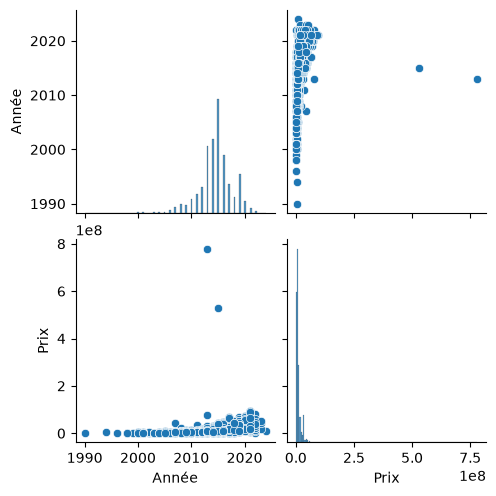

In [15]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

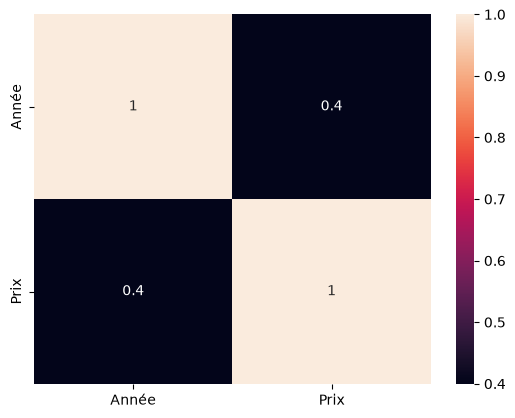

In [16]:
#matrice de correlation
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [17]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

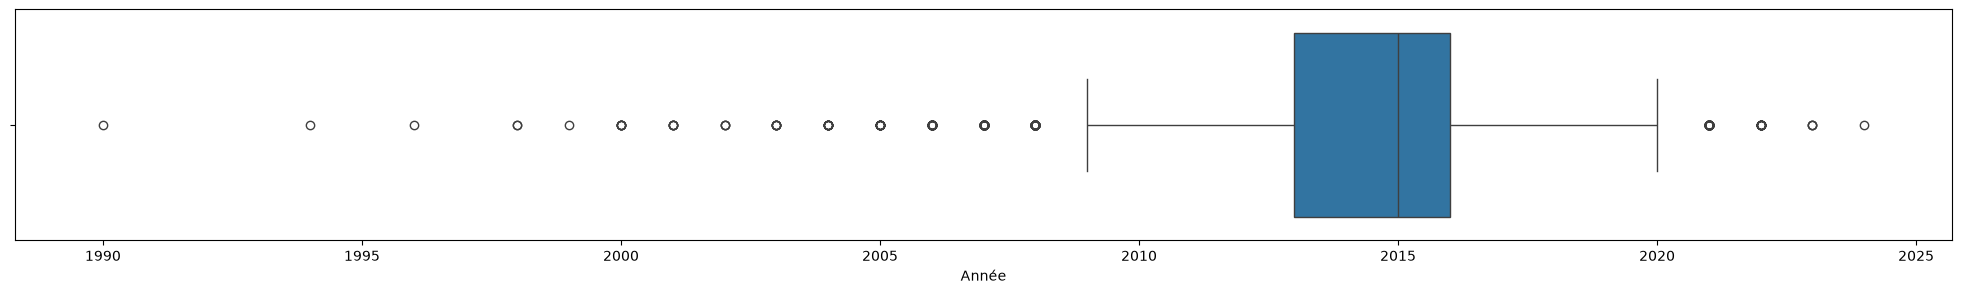

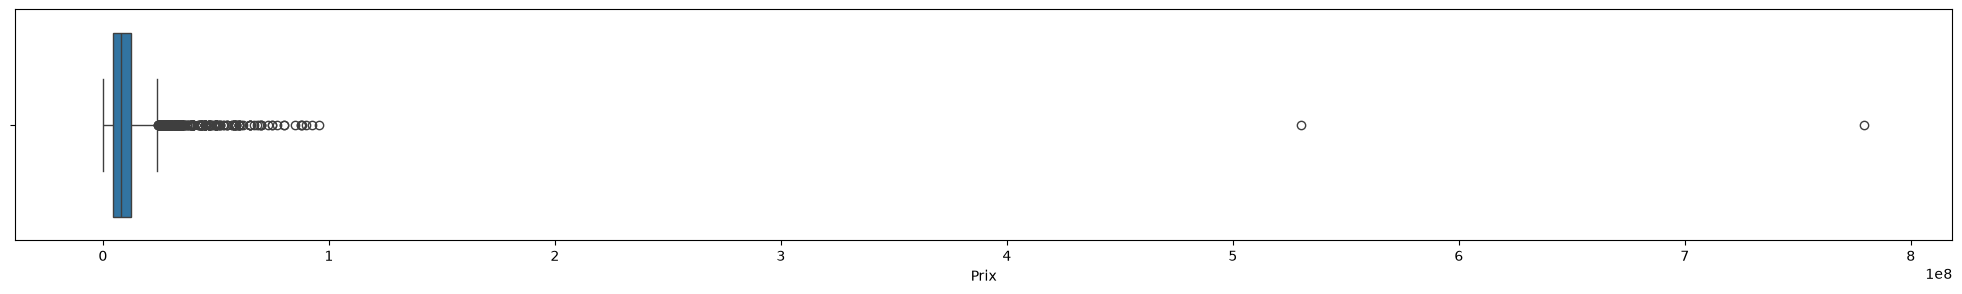

In [18]:
# boxplots des variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

###### <font color = 'bisque'> Preparation des données

In [19]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
# (copié du notebook taxi : sert à remplir les listes déroulantes de l'application)
uniques = []
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
# sauvegarde
jb.dump(uniques, '../models/car_data/uniques.joblib')

['../models/car_data/uniques.joblib']

In [20]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Un encodeur par variable (copié du notebook taxi) pour pouvoir les réutiliser dans l'application
encoders = []
for i in range(len(cat_data.columns)):
  encoder = LabelEncoder()
  encoder.fit(df[cat_data.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat_data.columns[i]] = encoder.transform(df[cat_data.columns[i]]) # encoder les valeurs
  encoders.append(encoder)

# sauvegarde les encodeurs
jb.dump(encoders, '../models/car_data/encoders.joblib')
df.head()

,Marque,Année,Boite_Vitesse,Quartier,Prix,Venant_Occasion
0,30,2017,0,49,9750000,1
1,13,2009,1,83,2500000,0
2,3,2015,0,11,15500000,0
3,13,2013,0,0,3800000,0
4,14,2014,0,38,7500000,1


In [21]:
from sklearn.impute import KNNImputer
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1 # interquantile
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [22]:
# imputation des valeurs extrêmes
# (conversion en float : pandas 3 refuse de mettre NaN dans une colonne d'entiers)
df = df.astype(float)
for col in quant_data.columns:
  impute_func(df,col)

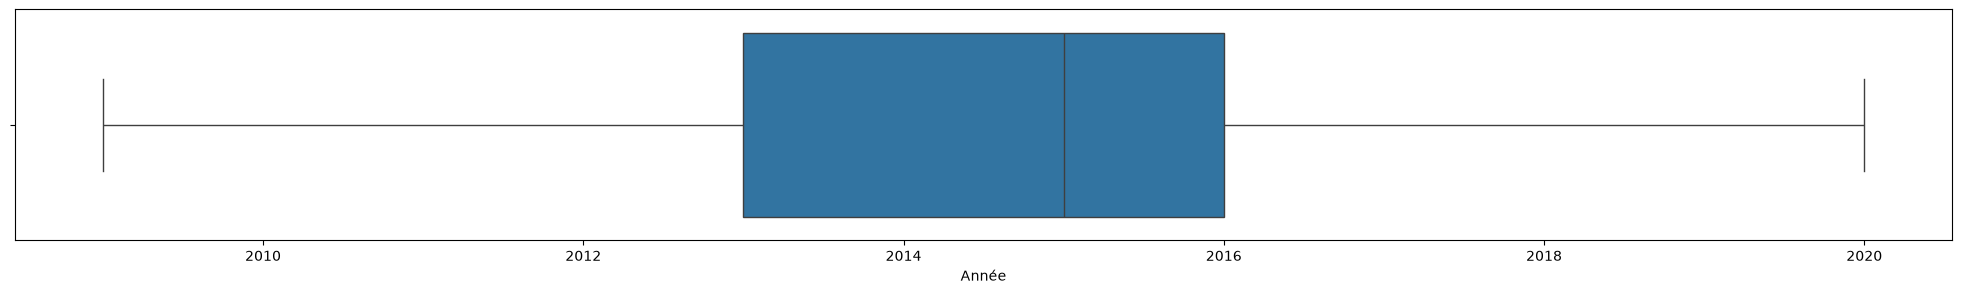

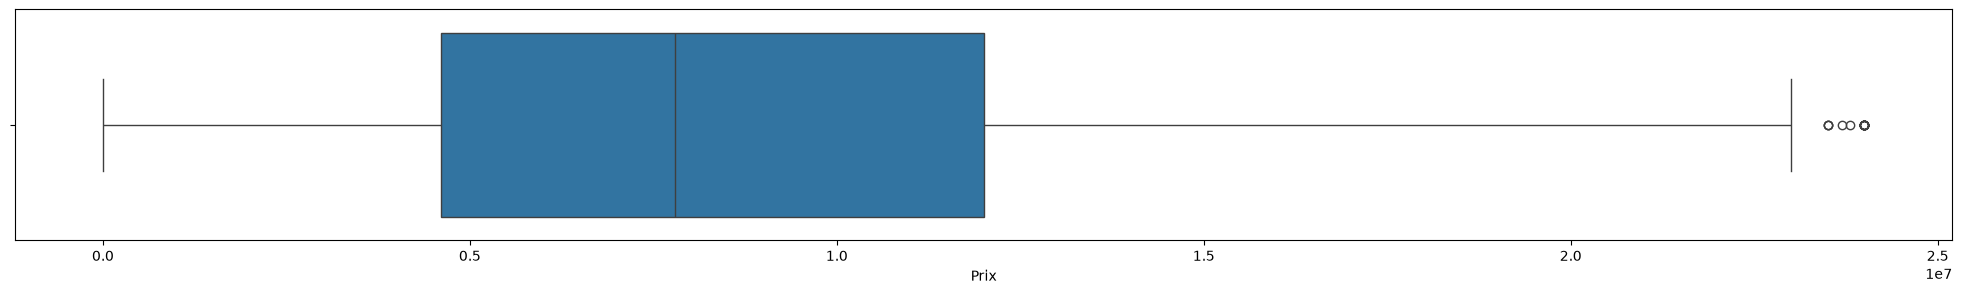

In [23]:
# Réafficher les boxplots
for col in quant_data.columns:
  boxplot_func(col)

In [24]:
# Fractionner les données en variables prédicteurs (x) et variable cible (y)
x = df.drop('Venant_Occasion', axis = 1).values
y = df.Venant_Occasion.values.astype(int)
x[:5], y[:5]

(array([[3.000e+01, 2.017e+03, 0.000e+00, 4.900e+01, 9.750e+06],
        [1.300e+01, 2.009e+03, 1.000e+00, 8.300e+01, 2.500e+06],
        [3.000e+00, 2.015e+03, 0.000e+00, 1.100e+01, 1.550e+07],
        [1.300e+01, 2.013e+03, 0.000e+00, 0.000e+00, 3.800e+06],
        [1.400e+01, 2.014e+03, 0.000e+00, 3.800e+01, 7.500e+06]]),
 array([1, 0, 0, 0, 1]))

In [25]:
# normaliser les données
from sklearn.preprocessing import MinMaxScaler # Z = (X-Xmin)/(Xmax - Xmin)
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
# sauvegarde du scaler (pour l'application)
jb.dump(scaler, '../models/car_data/scaler.joblib')
x[:5]

array([[0.66666667, 0.72727273, 0.        , 0.57647059, 0.40624998],
       [0.28888889, 0.        , 0.5       , 0.97647059, 0.10416663],
       [0.06666667, 0.54545455, 0.        , 0.12941176, 0.64583332],
       [0.28888889, 0.36363636, 0.        , 0.        , 0.1583333 ],
       [0.31111111, 0.45454545, 0.        , 0.44705882, 0.31249997]])

In [26]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size = 0.8, random_state = 42)# 80% -- 20%
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test, train_size = 0.5, random_state = 42)# 10% -- 10%

### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [27]:
from sklearn.model_selection import GridSearchCV, KFold
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params={"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# instantier le modèle Logistic regression
lg=LogisticRegression()
# instantier le modèle gridsearch
grid=GridSearchCV(lg,params,cv=cv)
# lancer la recherche
grid.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+03]), 'penalty': ['l1', 'l2']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the ve

In [28]:
# Afficher les paramètres optimaux
grid.best_params_

{'C': np.float64(0.021544346900318832), 'penalty': 'l2'}

###### <font color = 'bisque'> Entrainement du modèle

In [29]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
lg_model = LogisticRegression(**grid.best_params_)
lg_model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(0....4346900318832)
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to con

###### <font color ='bisque'>Evaluation du modèle

In [30]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  return acc, f1

In [31]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg, f1_lg = evaluation(lg_model)
print(f"Accuracy : {acc_lg} --- F1 score : {f1_lg}")

Accuracy : 0.7912885662431942 --- F1 score : 0.7912885662431942


In [32]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# noms des classes de la variable cible (dernier encodeur)
classnames = list(encoders[-1].classes_)
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=classnames)
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

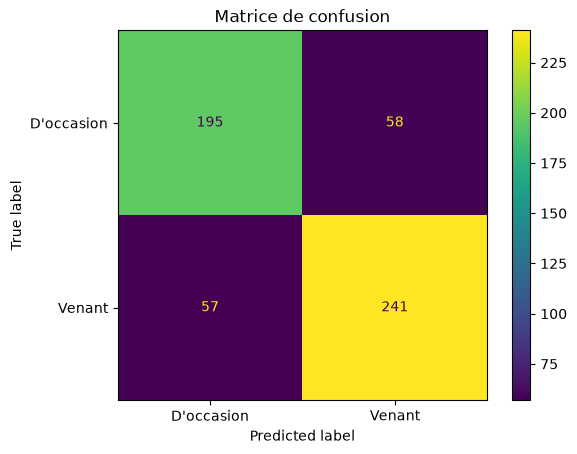

In [33]:
# Matrice de confusion
CM_visualisation(lg_model)

### <font color = 'teal'>Decision Tree<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [34]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier(random_state = 42)
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = cv)
# entrainer le modèle
grid__.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int

In [35]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'entropy', 'max_depth': np.int64(4)}

###### <font color = 'bisque'> Entrainement du modèle

In [36]:
# Entrainer le modèle en utilisant les paramètres optimaux
dt_model = DecisionTreeClassifier(random_state = 42, **grid__.best_params_)
dt_model.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(4)
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number 

###### <font color ='bisque'>Evaluation du modèle<font>

In [37]:
# Accuracy et F1 score du modèle sur les données de validation
acc_dt, f1_dt = evaluation(dt_model)
print(f"Accuracy : {acc_dt} --- F1 score : {f1_dt}")

Accuracy : 0.809437386569873 --- F1 score : 0.809437386569873


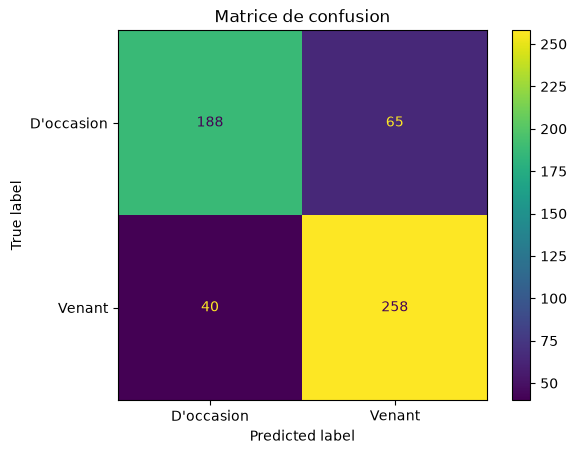

In [38]:
# Matrice de confusion
CM_visualisation(dt_model)

### <font color = 'teal'>Random Forest<font>

In [39]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier(random_state = 42)
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= cv)
# entrainer le modèle
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [np.int64(3), np.int64(4), ...], 'n_estimators': [np.int64(10), np.int64(20), ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Sup

In [40]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'entropy',
 'max_depth': np.int64(10),
 'n_estimators': np.int64(90)}

In [41]:
# Entrainer Random Forest en utilisant les paramètres optimaux
rf_model = RandomForestClassifier(random_state = 42, **grid.best_params_)
rf_model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",np.int64(90)
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(10)
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [42]:
acc_rf, f1_rf = evaluation(rf_model)
print(f"Accuracy : {acc_rf} --- F1 score : {f1_rf}")

Accuracy : 0.8039927404718693 --- F1 score : 0.8039927404718693


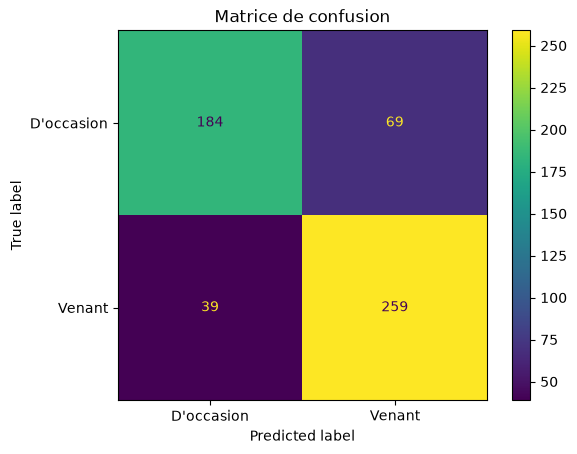

In [43]:
# Matrice de confusion
CM_visualisation(rf_model)

In [44]:
#diagrammes des performances
list_names = ['LG', 'DT', 'RF']
list_acc = [acc_lg, acc_dt, acc_rf]
list_f1 = [f1_lg, f1_dt,f1_rf]
list_final = [list_acc, list_f1]
for i in range(2):
  fig = px.bar(y=list_names, x= list_final[i], color = list_names, text_auto = True)
  fig.show()

In [45]:
# sauvegarder le modèle le plus performant (meilleure accuracy sur la validation)
list_models = [lg_model, dt_model, rf_model]
best_model = list_models[int(np.argmax(list_acc))]
print("Modèle le plus performant :", list_names[int(np.argmax(list_acc))])
jb.dump(best_model, '../models/car_data/best_model.joblib')

Modèle le plus performant : DT


['../models/car_data/best_model.joblib']

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [46]:
# Accuracy sur les données test (jamais vues par le modèle)
print("Accuracy test :", accuracy_score(y_test, best_model.predict(x_test)))
# echantillons
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# prédictions
y_pred_10 = best_model.predict(x_test_10)
for i in range(10):
  print(f"Prédiction {str(i +1)} : {classnames[y_pred_10[i]]}  -- {classnames[y_test_10[i]]}")

Accuracy test : 0.7822141560798548
Prédiction 1 : D'occasion  -- D'occasion
Prédiction 2 : Venant  -- Venant
Prédiction 3 : D'occasion  -- D'occasion
Prédiction 4 : Venant  -- Venant
Prédiction 5 : D'occasion  -- Venant
Prédiction 6 : D'occasion  -- D'occasion
Prédiction 7 : Venant  -- Venant
Prédiction 8 : Venant  -- D'occasion
Prédiction 9 : D'occasion  -- Venant
Prédiction 10 : D'occasion  -- D'occasion
